<a href="https://colab.research.google.com/github/Anagha-code12/AI-ML-Project/blob/main/AI_ML_Part_1_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Part 1: Data Extraction, Preprocessing & Exploratory Data Analysis**

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Chemicaldata.zip to Chemicaldata.zip


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

extract_path = "/content/chemical_dataset"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [ ]:
import os

csv_path = None

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".csv"):
            csv_path = os.path.join(root, file)
            break

print("CSV File Found:")
print(csv_path)

CSV File Found:
/content/chemical_dataset/chemical_process_timeseries.csv


In [ ]:
import pandas as pd

df = pd.read_csv(csv_path)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (777600, 21)


,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,selectivity,yield_pct,vibration_rms,motor_current,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min
0,2024-01-01 00:00:00,A,A_R1,0.000000,181.135558,15.791013,101.108882,79.154645,305.779931,0.724542,...,91.927424,82.032893,1.470297,45.882315,41.294083,180.0,12.0,0,0.0,NaN
1,2024-01-01 00:01:00,A,A_R1,0.000485,182.249820,15.706975,98.932369,NaN,302.283603,0.728999,...,91.581466,81.301503,1.425847,46.755905,42.080314,180.0,12.0,0,0.0,NaN
2,2024-01-01 00:02:00,A,A_R1,0.000970,183.129737,15.593397,99.792219,80.593736,305.814440,0.732519,...,91.895056,82.006626,1.448190,NaN,NaN,NaN,12.0,0,NaN,NaN
3,2024-01-01 00:03:00,A,A_R1,0.001454,183.020987,15.527333,99.854222,80.190444,304.436123,0.732084,...,91.544885,81.562261,1.473448,45.862171,41.275954,180.0,12.0,0,0.0,NaN
4,2024-01-01 00:04:00,A,A_R1,0.001939,183.077096,NaN,99.302349,78.571707,304.811418,0.732308,...,92.258005,82.411124,1.523491,46.880227,42.192204,180.0,12.0,0,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 777600 entries, 0 to 777599
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   timestamp             777600 non-null  object 
 1   operating_regime      777600 non-null  object 
 2   reactor_id            777600 non-null  object 
 3   ambient_temp_effect   731039 non-null  float64
 4   reactor_temp          730635 non-null  float64
 5   reactor_pressure      730457 non-null  float64
 6   feed_flow_rate        730840 non-null  float64
 7   coolant_flow_rate     730955 non-null  float64
 8   agitator_speed_rpm    730825 non-null  float64
 9   reaction_rate         730770 non-null  float64
 10  conversion_rate       731184 non-null  float64
 11  selectivity           730391 non-null  float64
 12  yield_pct             731076 non-null  float64
 13  vibration_rms         731141 non-null  float64
 14  motor_current         730983 non-null  float64
 15  

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ambient_temp_effect,731039.0,-0.001843,7.070747,-10.000000,-7.074538,-0.001697,7.067510,10.000000
reactor_temp,730635.0,187.966928,6.764989,177.793913,181.114731,191.453608,194.490403,202.349193
reactor_pressure,730457.0,16.621244,0.958705,15.214215,15.679560,16.026735,17.557269,18.335542
feed_flow_rate,730840.0,103.914662,4.299429,77.477094,99.975390,102.535852,107.992742,113.535969
coolant_flow_rate,730955.0,75.941397,4.435884,57.024631,71.981321,76.000170,79.962695,86.263795
agitator_speed_rpm,730825.0,299.995083,5.523135,273.136099,296.308714,299.983118,303.688205,330.603218
reaction_rate,730770.0,0.751721,0.026999,0.711814,0.724360,0.766517,0.777871,0.794623
conversion_rate,731184.0,99.352438,0.704188,88.574898,99.043724,99.390124,99.736575,101.112162
selectivity,730391.0,91.667593,0.201028,90.644932,91.531879,91.667629,91.803187,92.553263
yield_pct,731076.0,82.002868,0.403068,80.398878,81.714045,82.002136,82.291000,83.784775


In [ ]:
missing = df.isnull().sum()

missing

,0
timestamp,0
operating_regime,0
reactor_id,0
ambient_temp_effect,46561
reactor_temp,46965
reactor_pressure,47143
feed_flow_rate,46760
coolant_flow_rate,46645
agitator_speed_rpm,46775
reaction_rate,46830


In [ ]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

print("Remaining Shape:", df.shape)

Duplicates: 0
Remaining Shape: (777600, 21)


In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

df.head()

,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,selectivity,yield_pct,vibration_rms,motor_current,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min
0,2024-01-01 00:00:00,A,A_R1,0.000000,181.135558,15.791013,101.108882,79.154645,305.779931,0.724542,...,91.927424,82.032893,1.470297,45.882315,41.294083,180.0,12.0,0,0.0,NaN
1,2024-01-01 00:01:00,A,A_R1,0.000485,182.249820,15.706975,98.932369,NaN,302.283603,0.728999,...,91.581466,81.301503,1.425847,46.755905,42.080314,180.0,12.0,0,0.0,NaN
2,2024-01-01 00:02:00,A,A_R1,0.000970,183.129737,15.593397,99.792219,80.593736,305.814440,0.732519,...,91.895056,82.006626,1.448190,NaN,NaN,NaN,12.0,0,NaN,NaN
3,2024-01-01 00:03:00,A,A_R1,0.001454,183.020987,15.527333,99.854222,80.190444,304.436123,0.732084,...,91.544885,81.562261,1.473448,45.862171,41.275954,180.0,12.0,0,0.0,NaN
4,2024-01-01 00:04:00,A,A_R1,0.001939,183.077096,NaN,99.302349,78.571707,304.811418,0.732308,...,92.258005,82.411124,1.523491,46.880227,42.192204,180.0,12.0,0,NaN,NaN


In [ ]:
df['Year'] = df['timestamp'].dt.year
df['Month'] = df['timestamp'].dt.month
df['Day'] = df['timestamp'].dt.day
df['Hour'] = df['timestamp'].dt.hour

df.head()

,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min,Year,Month,Day,Hour
0,2024-01-01 00:00:00,A,A_R1,0.000000,181.135558,15.791013,101.108882,79.154645,305.779931,0.724542,...,41.294083,180.0,12.0,0,0.0,NaN,2024,1,1,0
1,2024-01-01 00:01:00,A,A_R1,0.000485,182.249820,15.706975,98.932369,NaN,302.283603,0.728999,...,42.080314,180.0,12.0,0,0.0,NaN,2024,1,1,0
2,2024-01-01 00:02:00,A,A_R1,0.000970,183.129737,15.593397,99.792219,80.593736,305.814440,0.732519,...,NaN,NaN,12.0,0,NaN,NaN,2024,1,1,0
3,2024-01-01 00:03:00,A,A_R1,0.001454,183.020987,15.527333,99.854222,80.190444,304.436123,0.732084,...,41.275954,180.0,12.0,0,0.0,NaN,2024,1,1,0
4,2024-01-01 00:04:00,A,A_R1,0.001939,183.077096,NaN,99.302349,78.571707,304.811418,0.732308,...,42.192204,180.0,12.0,0,NaN,NaN,2024,1,1,0


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

categorical = df.select_dtypes(include='object').columns

categorical

Index(['operating_regime', 'reactor_id'], dtype='object')

In [ ]:
for col in categorical:
    df[col] = encoder.fit_transform(df[col])

df.head()

,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min,Year,Month,Day,Hour
0,2024-01-01 00:00:00,0,0,0.000000,181.135558,15.791013,101.108882,79.154645,305.779931,0.724542,...,41.294083,180.0,12.0,0,0.0,NaN,2024,1,1,0
1,2024-01-01 00:01:00,0,0,0.000485,182.249820,15.706975,98.932369,NaN,302.283603,0.728999,...,42.080314,180.0,12.0,0,0.0,NaN,2024,1,1,0
2,2024-01-01 00:02:00,0,0,0.000970,183.129737,15.593397,99.792219,80.593736,305.814440,0.732519,...,NaN,NaN,12.0,0,NaN,NaN,2024,1,1,0
3,2024-01-01 00:03:00,0,0,0.001454,183.020987,15.527333,99.854222,80.190444,304.436123,0.732084,...,41.275954,180.0,12.0,0,0.0,NaN,2024,1,1,0
4,2024-01-01 00:04:00,0,0,0.001939,183.077096,NaN,99.302349,78.571707,304.811418,0.732308,...,42.192204,180.0,12.0,0,NaN,NaN,2024,1,1,0


In [ ]:
df.dtypes

,0
timestamp,datetime64[ns]
operating_regime,int64
reactor_id,int64
ambient_temp_effect,float64
reactor_temp,float64
reactor_pressure,float64
feed_flow_rate,float64
coolant_flow_rate,float64
agitator_speed_rpm,float64
reaction_rate,float64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numeric_columns = df.select_dtypes(include=['int64','float64']).columns

numeric_columns = numeric_columns.drop('fault_type')

df[numeric_columns] = scaler.fit_transform(df[numeric_columns])

df.head()

,timestamp,operating_regime,reactor_id,ambient_temp_effect,reactor_temp,reactor_pressure,feed_flow_rate,coolant_flow_rate,agitator_speed_rpm,reaction_rate,...,power_consumption_kw,temp_setpoint,pressure_setpoint,fault_type,efficiency_loss_pct,time_to_fault_min,Year,Month,Day,Hour
0,2024-01-01 00:00:00,-1.0,-1.46385,0.000261,-1.009813,-0.865993,-0.652594,0.724376,1.047386,-1.006642,...,-0.230849,-1.000402,-0.999401,0,-0.179721,NaN,2024,1,1,0
1,2024-01-01 00:01:00,-1.0,-1.46385,0.000329,-0.845103,-0.953651,-1.158828,NaN,0.414352,-0.841562,...,1.477597,-1.000402,-0.999401,0,-0.179721,NaN,2024,1,1,0
2,2024-01-01 00:02:00,-1.0,-1.46385,0.000398,-0.715034,-1.072121,-0.958836,1.048797,1.053634,-0.711201,...,NaN,NaN,-0.999401,0,NaN,NaN,2024,1,1,0
3,2024-01-01 00:03:00,-1.0,-1.46385,0.000466,-0.731109,-1.141031,-0.944414,0.957881,0.804080,-0.727312,...,-0.270243,-1.000402,-0.999401,0,-0.179721,NaN,2024,1,1,0
4,2024-01-01 00:04:00,-1.0,-1.46385,0.000535,-0.722815,NaN,-1.072774,0.592962,0.872030,-0.719000,...,1.720729,-1.000402,-0.999401,0,NaN,NaN,2024,1,1,0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

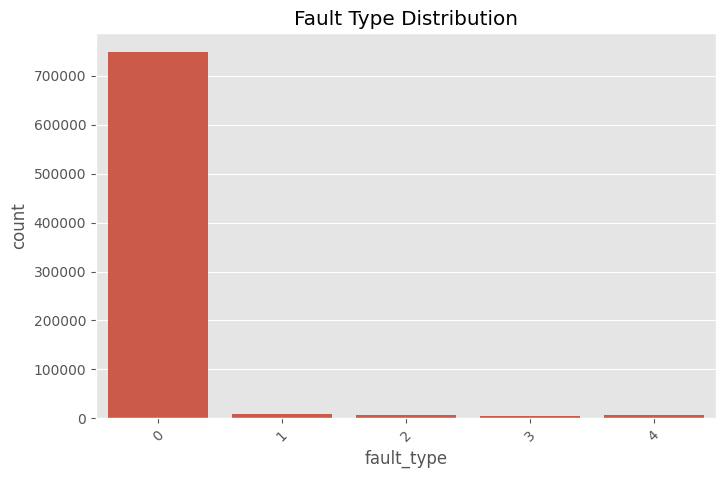

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(x='fault_type', data=df)

plt.title("Fault Type Distribution")
plt.xticks(rotation=45)
plt.show()

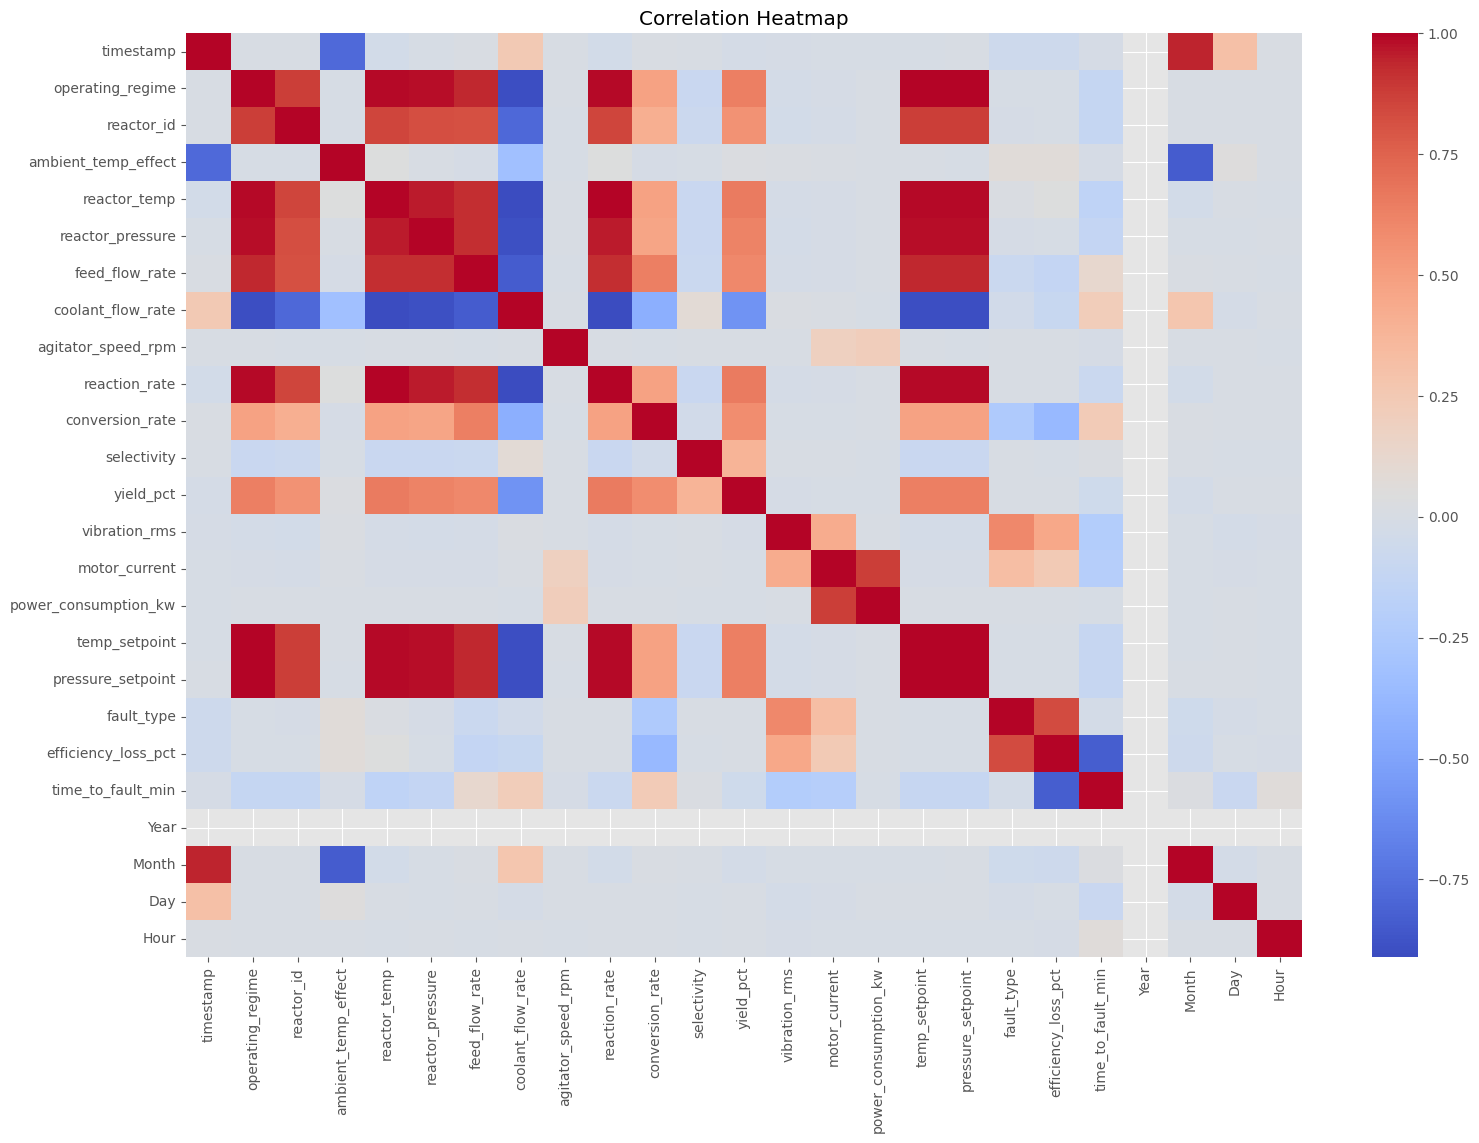

In [ ]:
plt.figure(figsize=(18,12))

sns.heatmap(df.corr(),
            cmap='coolwarm',
            annot=False)

plt.title("Correlation Heatmap")

plt.show()

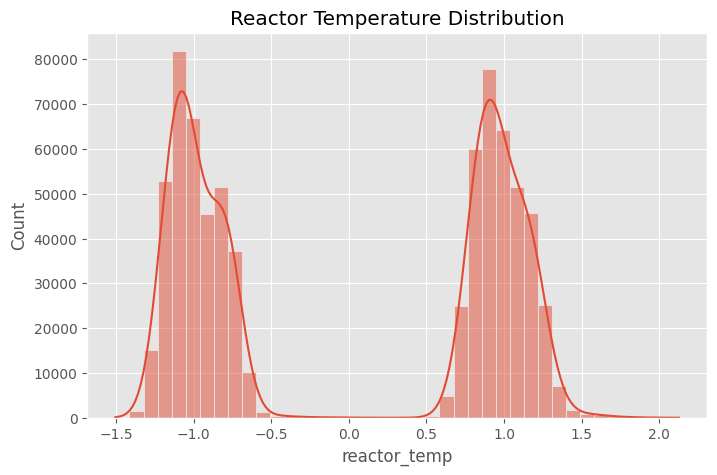

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['reactor_temp'],
             bins=40,
             kde=True)

plt.title("Reactor Temperature Distribution")

plt.show()

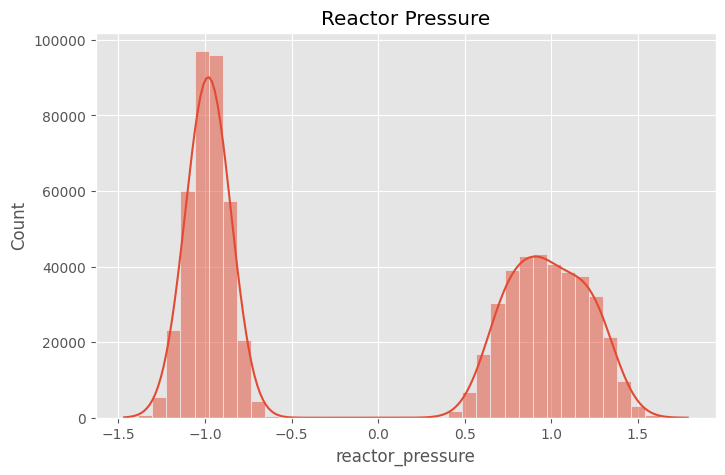

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['reactor_pressure'],
             bins=40,
             kde=True)

plt.title("Reactor Pressure")

plt.show()

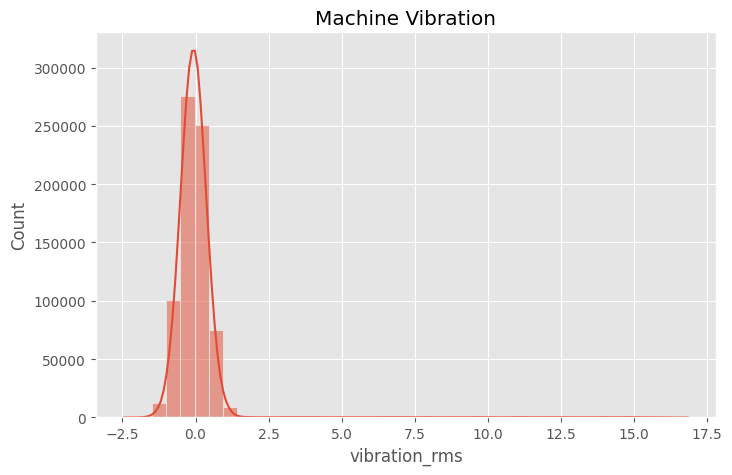

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['vibration_rms'],
             bins=40,
             kde=True)

plt.title("Machine Vibration")

plt.show()

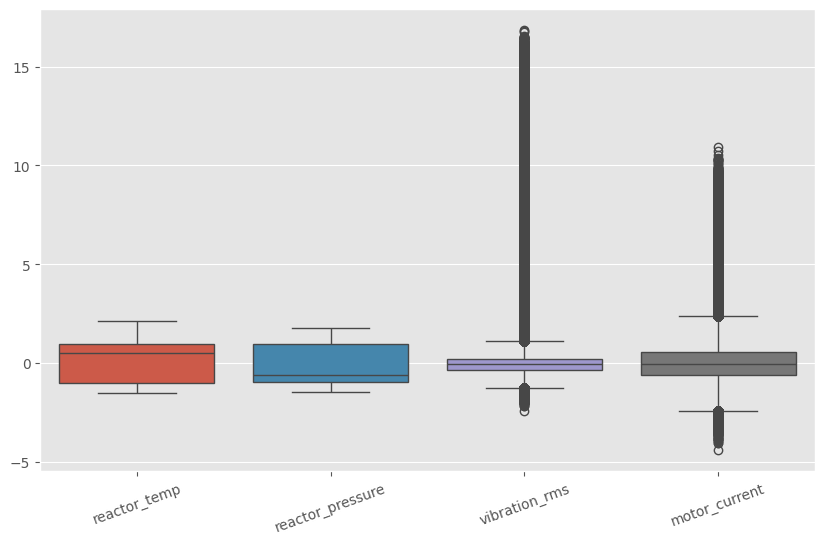

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(data=df[['reactor_temp',
                     'reactor_pressure',
                     'vibration_rms',
                     'motor_current']])

plt.xticks(rotation=20)

plt.show()

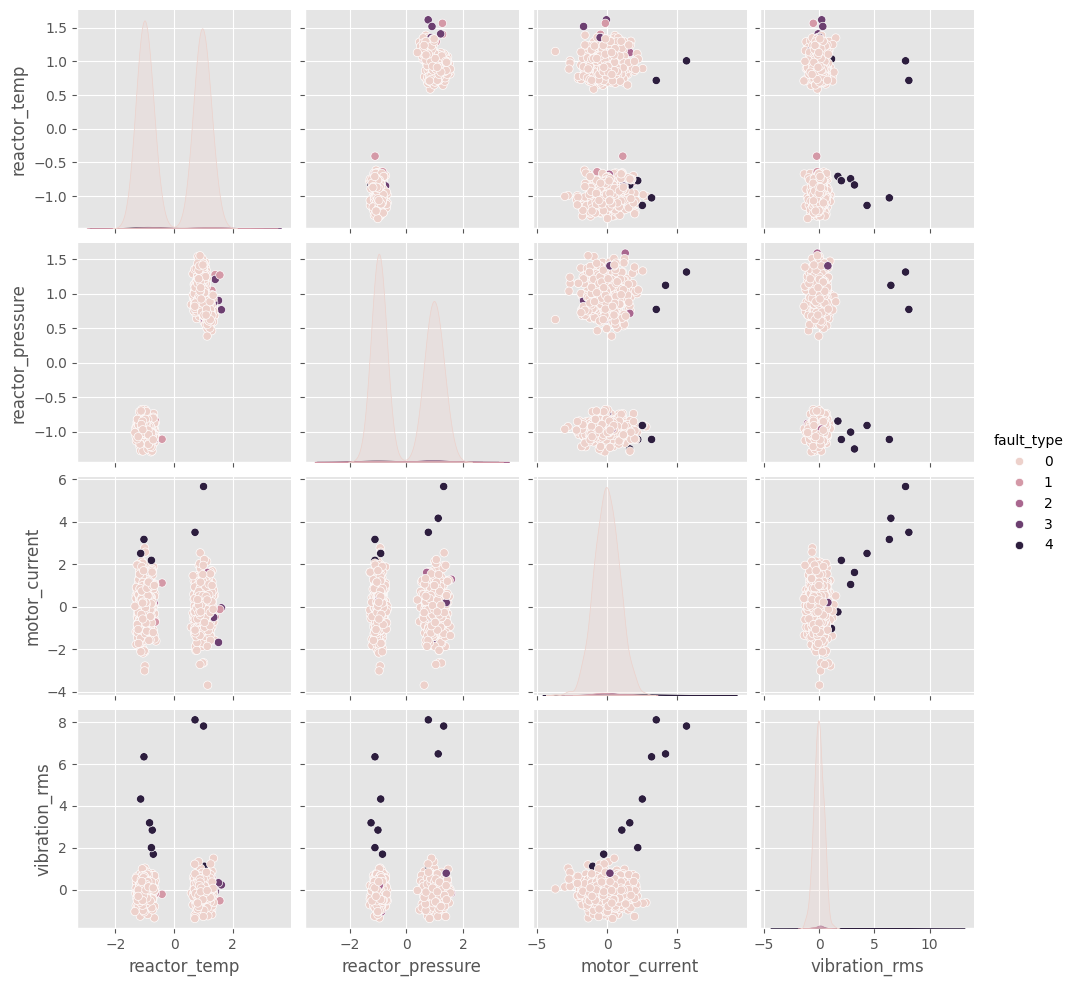

In [ ]:
sample = df.sample(1000, random_state=42)

sns.pairplot(sample[['reactor_temp',
                     'reactor_pressure',
                     'motor_current',
                     'vibration_rms',
                     'fault_type']],
             hue='fault_type')

plt.show()

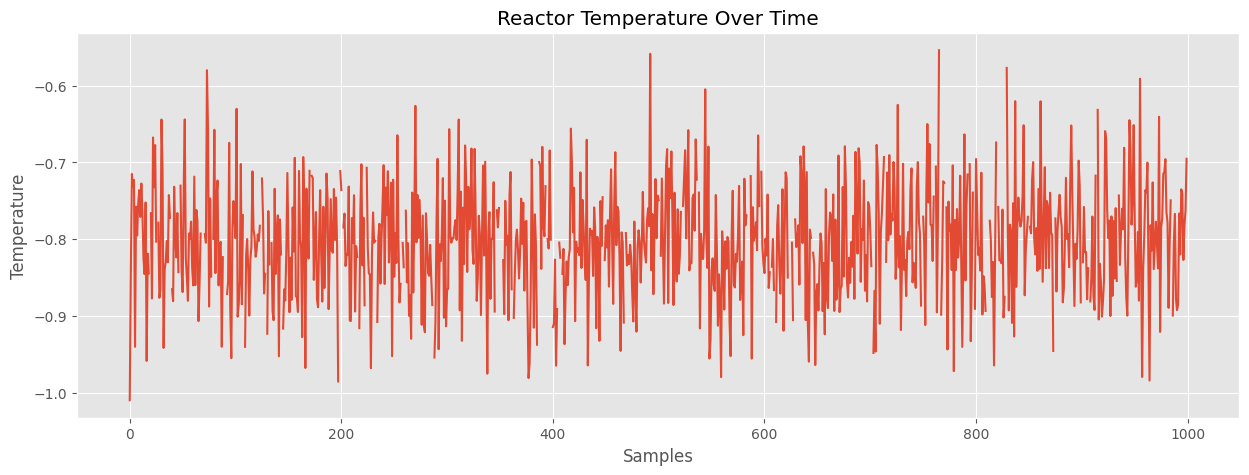

In [ ]:
sample = df.head(1000)

plt.figure(figsize=(15,5))

plt.plot(sample['reactor_temp'])

plt.title("Reactor Temperature Over Time")

plt.xlabel("Samples")

plt.ylabel("Temperature")

plt.show()

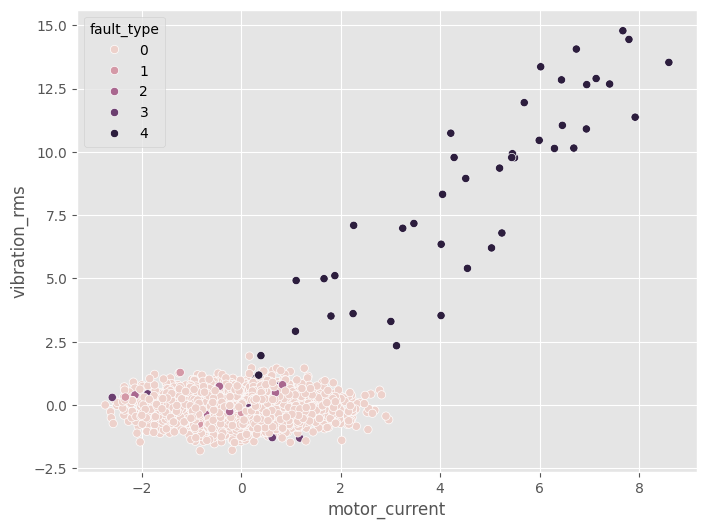

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(x='motor_current',
                y='vibration_rms',
                hue='fault_type',
                data=df.sample(5000))

plt.show()

In [ ]:
processed_file = "/content/processed_chemical_dataset.csv"

df.to_csv(processed_file, index=False)

print("Saved Successfully!")

print(processed_file)

Saved Successfully!
/content/processed_chemical_dataset.csv


In [ ]:
from google.colab import files

files.download(processed_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>